# Dimensionality study — does the Asimov property break with bin occupancy?

**Question.** The NSBI analysis violates the Asimov property (Asimov scan ≠ median of toy scans)
at 1–10 fb$^{-1}$; the 1D histogram does not. Hypothesis: the driver is **per-bin occupancy** —
NSBI is effectively an astronomically fine histogram in 16 dimensions — not machine learning per
se. Test: run the *same histogram likelihood* in $d = 1\ldots4$ observables so occupancy spans
five orders of magnitude, and watch where Asimov vs median(toys) starts to disagree.

**Design** (approved in `docs/dimensionality-study.md`): occupancy grid $d\in\{1,2,3,4\}$
(10 bins/axis) $\times$ lumi $\in\{1,10,100,1000\}$ fb$^{-1}$ — constant occupancy runs along the
diagonals — plus a **control** at fixed total bins ($\approx16$) to separate "dimension" from
"cells". Axes: $m_{4\ell}$, $m_{Z2}$, $\cos\theta^*$, $m_{Z1}$. 200 toys per point, seed 42,
$\mu \in [0, 8]$ (161 points; wider than Phase 1 so 1σ intervals can close at low occupancy).

**How to use.** Run top to bottom (~5 min, CPU only, inside the container with
`PYTHONNOUSERSITE=1`). Parameters in one cell; plotting cells separate from the analysis.
Companion notebook: `histogram_reproduction.ipynb` (the 1D baseline).

## 1. Imports and engine path

In [1]:
import os, sys, json, itertools
import numpy as np
import torch
import hist
import vector
import matplotlib.pyplot as plt

ROOT    = os.environ.get('SBI_ROOT', '/project/atlas/Users/mfernand/SBI_shortcomings')
SUBREPO = os.path.join(ROOT, 'asimov-aymptotics-check')
if SUBREPO not in sys.path:
    sys.path.insert(0, SUBREPO)

from physics.simulation import mcfm, toys
from physics.hstar import sigstr
from physics.analysis import zz4l
from stats.binned import poisson_log_likelihood_scan, poisson_log_likelihood_scan_toys

torch.set_default_dtype(torch.float32)
print('engine:', SUBREPO)

engine: /project/atlas/Users/mfernand/SBI_shortcomings/asimov-aymptotics-check


## 2. Parameters

In [2]:
# ---- adjust here --------------------------------------------------------------
DATA_DIR  = os.environ.get('DATASET_DIR', os.path.join(ROOT, 'data/zz4l/ggzz4l_sm'))
LUMIS     = [1., 10., 100., 1000.]        # fb^-1
N_ROWS    = int(3e5)
N_TOYS    = 200
SEED      = 42
MU_SCAN   = torch.linspace(0.0, 8.0, 161) # wider than Phase 1: let 1-sigma close at low occupancy
TOY_CHUNK = 50                            # toys per chunk in the binned-NLL call (memory guard at 4D)
# -------------------------------------------------------------------------------
mu_np = MU_SCAN.numpy()
N_EXP_1FB = 5.656                         # expected SBI events at 1 fb^-1 (docs/context.md)

## 3. Load events and build the four observables

Beyond the CSV columns ($m_{4\ell}$, $m_{Z1}$, $m_{Z2}$) we need $\cos\theta^*$ — the production
angle of the $Z_1$ in the four-lepton rest frame. The CSV has no ready-made column, but it carries
the Z-paired lepton four-vectors (`Z1_l1_px` …), so we build the four leptons with the `vector`
library and call the sub-repo's own `AngularVariables.calc_cth_star` (Tei's function — arXiv
definition in its docstring). Note: the calculator's `__call__` expects `l1_px`-style columns this
CSV doesn't have, hence calling the method directly with the Z-paired vectors.

In [3]:
zlep_cols = [f'Z{z}_l{l}_{c}' for z in (1, 2) for l in (1, 2) for c in ('px', 'py', 'pz', 'E')]
columns = ['4l_mass', 'Z1_mass', 'Z2_mass'] + zlep_cols

events = mcfm.from_csv(file_path=os.path.join(DATA_DIR, 'ggzz4l_sbi.csv'),
                       kinematics=columns, cross_section=np.prod(json.load(open(os.path.join(DATA_DIR, 'ggzz4l_xs.json')))['sbi']),
                       n_rows=N_ROWS)
kin = events.kinematics

leptons = [vector.array({'px': kin[f'Z{z}_l{l}_px'], 'py': kin[f'Z{z}_l{l}_py'],
                         'pz': kin[f'Z{z}_l{l}_pz'], 'E':  kin[f'Z{z}_l{l}_E']})
           for z in (1, 2) for l in (1, 2)]
cth_star = np.asarray(zz4l.AngularVariables().calc_cth_star(*leptons))

OBS = {
    'm4l':  kin['4l_mass'].values,
    'mZ2':  kin['Z2_mass'].values,
    'cth*': cth_star,
    'mZ1':  kin['Z1_mass'].values,
}
print({k: (v.min().round(2), v.max().round(2)) for k, v in OBS.items()})

{'m4l': (180.0, 1198.33), 'mZ2': (70.0, 107.53), 'cth*': (-1.0, 1.0), 'mZ1': (74.4, 110.0)}


## 4. Binning and the grid of configurations

Per-axis edges: log bins for $m_{4\ell}$ (Phase-1 choice), linear for the masses over their
0.5–99.5 percentile span, uniform $[-1,1]$ for $\cos\theta^*$. Two families of configurations:
**occupancy scan** (10 bins/axis, so $N_{\rm bins}=10^d$) and **control** (total bins fixed at
$\approx16$ while $d$ varies).

In [4]:
def edges_lin(x, n):
    lo, hi = np.percentile(x, [0.5, 99.5])
    return np.linspace(lo, hi, n + 1)

def axis(obs_name, n):
    if obs_name == 'm4l':
        return hist.axis.Regular(n, 180, 1000, transform=hist.axis.transform.log)
    if obs_name == 'cth*':
        return hist.axis.Regular(n, -1, 1)
    return hist.axis.Variable(edges_lin(OBS[obs_name], n))

AXIS_ORDER = ['m4l', 'mZ2', 'cth*', 'mZ1']
CONFIGS = {}
for d in (1, 2, 3, 4):                                   # occupancy scan: 10 bins/axis
    names = AXIS_ORDER[:d]
    CONFIGS[f'occ_{d}d'] = (names, [axis(nm, 10) for nm in names])
for d, per_axis in [(1, [16]), (2, [4, 4]), (3, [2, 2, 4]), (4, [2, 2, 2, 2])]:   # control: ~16 bins
    names = AXIS_ORDER[:d]
    CONFIGS[f'ctl_{d}d'] = (names, [axis(nm, n) for nm, n in zip(names, per_axis)])

for name, (names, axes) in CONFIGS.items():
    print(f"{name}: {' x '.join(names)}  ->  {np.prod([a.size for a in axes])} bins")

occ_1d: m4l  ->  10 bins
occ_2d: m4l x mZ2  ->  100 bins
occ_3d: m4l x mZ2 x cth*  ->  1000 bins
occ_4d: m4l x mZ2 x cth* x mZ1  ->  10000 bins
ctl_1d: m4l  ->  16 bins
ctl_2d: m4l x mZ2  ->  16 bins
ctl_3d: m4l x mZ2 x cth*  ->  16 bins
ctl_4d: m4l x mZ2 x cth* x mZ1  ->  16 bins


### 4.1 The four 1D spectra (weighted, 1 fb$^{-1}$)
Sanity check of the observables and the binning spans before anything is scanned.

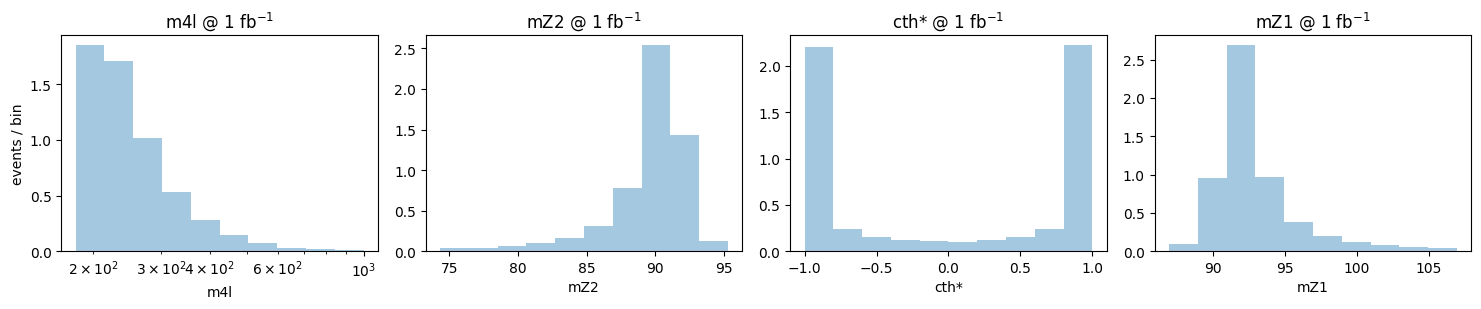

In [5]:
w_sm, _ = sigstr.scale(events, signal_strength=1.0, ignore_interference=False)
fig, axes4 = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, nm in zip(axes4, AXIS_ORDER):
    a = axis(nm, 10)
    h = hist.Hist(a); h.fill(OBS[nm], weight=np.asarray(w_sm) * 1.0)
    ax.stairs(h.values(), a.edges, fill=True, alpha=0.4, color='C0')
    ax.set_xlabel(nm); ax.set_title(f'{nm} @ 1 fb$^{{-1}}$')
    if nm == 'm4l': ax.set_xscale('log')
axes4[0].set_ylabel('events / bin')
fig.tight_layout(); plt.show()

## 5. Scans: Asimov + toys per (configuration × luminosity)

Histogram contents are linear in the event weights, so the Asimov and 161-point expected
histograms are filled **once** at unit luminosity per configuration and scaled by $L$. Toys are
per-luminosity (Poisson draws at $w\,L$) but **shared across configurations** (they are per-event
weights, independent of binning). The toy NLL is evaluated in chunks of `TOY_CHUNK` to keep the
$(N_{\rm bins} \times 161 \times 200)$ broadcast under control at 4D.

In [6]:
w_scan, _ = sigstr.scale(events, signal_strength=MU_SCAN, ignore_interference=False)   # (N, 161)
w_scan = np.asarray(w_scan)

def fill_flat(names, axes, weights):
    h = hist.Hist(*axes)
    h.fill(*[OBS[nm] for nm in names], weight=np.asarray(weights))
    return h.values().flatten()

UNIT = {}
for cname, (names, axes) in CONFIGS.items():
    nu_asimov_u = fill_flat(names, axes, w_sm)
    nu_exp_u    = np.stack([fill_flat(names, axes, w_scan[:, m]) for m in range(w_scan.shape[1])], 1)
    UNIT[cname] = (nu_asimov_u, nu_exp_u)
    print(f'{cname}: filled ({nu_exp_u.shape[0]} bins x {nu_exp_u.shape[1]} mu-points)')

occ_1d: filled (10 bins x 161 mu-points)


occ_2d: filled (100 bins x 161 mu-points)


occ_3d: filled (1000 bins x 161 mu-points)


occ_4d: filled (10000 bins x 161 mu-points)


ctl_1d: filled (16 bins x 161 mu-points)


ctl_2d: filled (16 bins x 161 mu-points)


ctl_3d: filled (16 bins x 161 mu-points)


ctl_4d: filled (16 bins x 161 mu-points)


In [7]:
def nll_toys_chunked(n_obs, nu_exp):
    out = []
    for t0 in range(0, n_obs.shape[1], TOY_CHUNK):
        out.append(-2 * poisson_log_likelihood_scan_toys(n_obs[:, t0:t0+TOY_CHUNK], nu_exp))
    return torch.cat(out, dim=1)

RES = {}
for L in LUMIS:
    nu_toys = toys.generate(w_sm * L, n_toys=N_TOYS, random_state=SEED)     # (200, N) — shared across configs
    nu_toys = np.asarray(nu_toys)
    for cname, (names, axes) in CONFIGS.items():
        nu_asimov = UNIT[cname][0] * L
        nu_exp    = UNIT[cname][1] * L
        n_obs = np.stack([fill_flat(names, axes, nu_toys[i, :]) for i in range(N_TOYS)], 1)
        nll_a = -2 * poisson_log_likelihood_scan(nu_asimov, nu_exp)
        nll_t = nll_toys_chunked(torch.tensor(n_obs), nu_exp)
        RES[(cname, L)] = dict(nll_asimov=nll_a, nll_toys=nll_t,
                               n_obs=torch.tensor(n_obs, dtype=torch.float32),  # kept for the BB-lite overlay (§11)
                               n_bins=nu_exp.shape[0], occ=N_EXP_1FB * L / nu_exp.shape[0])
    print(f'{L:>6.0f} fb^-1 done')

/project/atlas/Users/mfernand/SBI_shortcomings/asimov-aymptotics-check/physics/simulation/toys.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  weights = torch.tensor(nu, dtype=torch.float64)


     1 fb^-1 done


    10 fb^-1 done


   100 fb^-1 done


  1000 fb^-1 done


## 6. Metrics

Per point: Asimov and median-of-toys $\hat\mu$; $\Delta(-2\ln L)=1$ interval widths (nan when the
interval does not close inside $\mu\in[0,8]$); `ratio` = width(median)/width(Asimov) — the
Asimov-property metric (1 = holds; <1 = toys narrower, the NSBI failure direction); `maxdiff` =
max $|A - M|$ over the grid; `bad toys` = toys with a non-finite scan (an observed event in a bin
with zero expectation — possible at very low occupancy).

In [8]:
def interval(nll):
    d = (nll - nll[torch.isfinite(nll)].min()).numpy(); g = mu_np
    d = np.where(np.isfinite(d), d, np.inf)
    i = int(np.argmin(d))
    lo = np.interp(1.0, d[:i+1][::-1], g[:i+1][::-1]) if i > 0 and d[:i+1].max() >= 1 else np.nan
    hi = np.interp(1.0, d[i:], g[i:]) if i < len(d)-1 and d[i:].max() >= 1 else np.nan
    return g[i], lo, hi

# Median conventions (adopted 2026-07-13, PROVISIONAL — pending team ratification, foundations §8):
#   primary   = np.median of per-toy min-subtracted (Δ) curves — matches the scalar-statistic theorem
#   secondary = np.median of raw curves — retains per-toy location scatter (estimator variance)
#   torch.median retired: lower-middle element at even n biases high-D medians
def med_curves(nll_toys_finite):
    t = nll_toys_finite.numpy()
    delta = t - t.min(axis=0, keepdims=True)
    return (torch.from_numpy(np.median(delta, axis=1)),
            torch.from_numpy(np.median(t, axis=1)))

TAB = {}
print(f"{'config':>8} {'lumi':>6} {'bins':>6} {'occ':>10} {'mu_A':>6} {'mu_M':>6} {'w_A':>7} {'w_M':>7} "
      f"{'ratio_D':>8} {'ratio_raw':>9} {'maxdiff':>8} {'bad':>4}")
for (cname, L), r in RES.items():
    finite = torch.isfinite(r['nll_toys']).all(dim=0)
    med_d, med_raw = med_curves(r['nll_toys'][:, finite])
    ha, la, ua = interval(r['nll_asimov'])
    hm, lm, um = interval(med_d)
    hr, lr, ur = interval(med_raw)
    wa, wm, wr = ua - la, um - lm, ur - lr
    da = r['nll_asimov'] - r['nll_asimov'].min(); dm = med_d - med_d.min()
    maxdiff = float((da - dm).abs().max())
    TAB[(cname, L)] = dict(occ=r['occ'], ratio=wm/wa, ratio_raw=wr/wa, wa=wa, wm=wm, maxdiff=maxdiff,
                           mu_a=ha, mu_m=hm, bad=int((~finite).sum()), n_bins=r['n_bins'])
    print(f"{cname:>8} {L:>6.0f} {r['n_bins']:>6} {r['occ']:>10.2e} {ha:>6.2f} {hm:>6.2f} "
          f"{wa:>7.3f} {wm:>7.3f} {wm/wa:>8.3f} {wr/wa:>9.3f} {maxdiff:>8.3f} {int((~finite).sum()):>4}")

  config   lumi   bins        occ   mu_A   mu_M     w_A     w_M  ratio_D ratio_raw  maxdiff  bad
  occ_1d      1     10   5.66e-01   1.00   0.65     nan     nan      nan       nan    0.590    0
  occ_2d      1    100   5.66e-02   1.00   0.55     nan     nan      nan       nan    0.606    0
  occ_3d      1   1000   5.66e-03   1.00   0.65     nan     nan      nan       nan    0.538    0
  occ_4d      1  10000   5.66e-04   1.00   0.60     nan     nan      nan       nan    0.540    0
  ctl_1d      1     16   3.53e-01   1.00   0.50     nan     nan      nan       nan    0.485    0
  ctl_2d      1     16   3.53e-01   1.00   0.55     nan     nan      nan       nan    0.512    0
  ctl_3d      1     16   3.53e-01   1.00   0.65     nan     nan      nan       nan    0.509    0
  ctl_4d      1     16   3.53e-01   1.00   0.65     nan     nan      nan       nan    0.546    0
  occ_1d     10     10   5.66e+00   1.00   0.55     nan     nan      nan       nan    0.318    0
  occ_2d     10    100   5.66e

## 7. Main figure — the occupancy grid

Rows = dimensionality (10 bins/axis), columns = luminosity. Solid = median of toys, dashed =
Asimov. Along any diagonal the mean occupancy is constant. If occupancy drives the Asimov-property
violation, panels should degrade toward the bottom-left corner and look alike along diagonals.

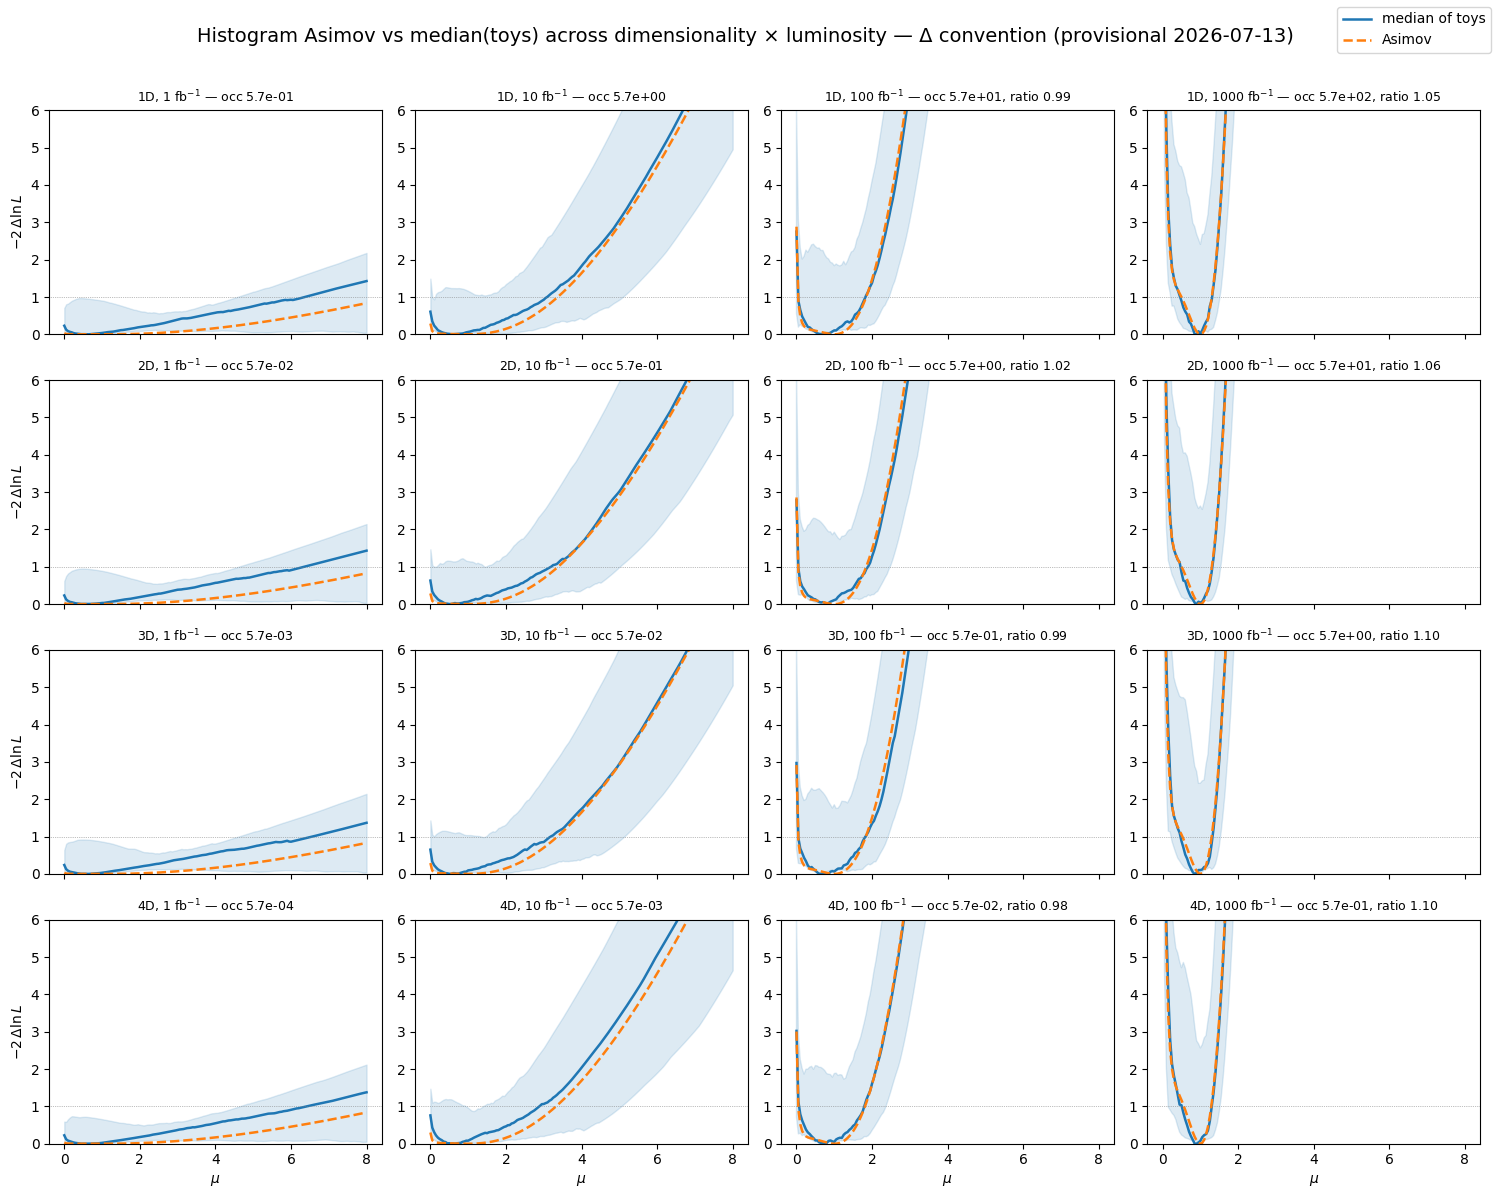

In [9]:
fig, axg = plt.subplots(4, 4, figsize=(15, 12), sharex=True)
for i, d in enumerate((1, 2, 3, 4)):
    for j, L in enumerate(LUMIS):
        ax = axg[i, j]; r = RES[(f'occ_{d}d', L)]
        finite = torch.isfinite(r['nll_toys']).all(dim=0)
        tm  = r['nll_toys'][:, finite] - r['nll_toys'][:, finite].min(dim=0).values
        med = torch.from_numpy(np.median(tm.numpy(), axis=1))   # Δ convention (primary, 2026-07-13)
        lo, hi = torch.quantile(tm, torch.tensor([0.16, 0.84]), dim=1).numpy()
        ax.fill_between(mu_np, lo, hi, alpha=0.15, color='C0')
        ax.plot(mu_np, (med - med.min()).numpy(), '-', color='C0', lw=1.8,
                label='median of toys' if (i, j) == (0, 0) else None)
        ax.plot(mu_np, (r['nll_asimov'] - r['nll_asimov'].min()).numpy(), '--', color='C1', lw=1.8,
                label='Asimov' if (i, j) == (0, 0) else None)
        ax.axhline(1, color='grey', lw=0.5, ls=':')
        ax.set_ylim(0, 6)
        t = TAB[(f'occ_{d}d', L)]
        ax.set_title(f"{d}D, {L:.0f} fb$^{{-1}}$ — occ {t['occ']:.1e}" + (f", ratio {t['ratio']:.2f}" if np.isfinite(t['ratio']) else ""), fontsize=9)
        if i == 3: ax.set_xlabel(r'$\mu$')
        if j == 0: ax.set_ylabel(r'$-2\,\Delta\ln L$')
fig.legend(loc='upper right', fontsize=10)
fig.suptitle('Histogram Asimov vs median(toys) across dimensionality × luminosity — Δ convention (provisional 2026-07-13)', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

## 8. The collapse plot — is occupancy the whole story?

Every (configuration, luminosity) point — occupancy scan *and* control — plotted against its mean
occupancy $N_{\rm exp}/N_{\rm bins}$. If occupancy is the driver, points of all colours should
fall on one curve; the control points (stars, ~16 bins at every $d$) should sit where their
occupancy puts them, not where their dimensionality does.

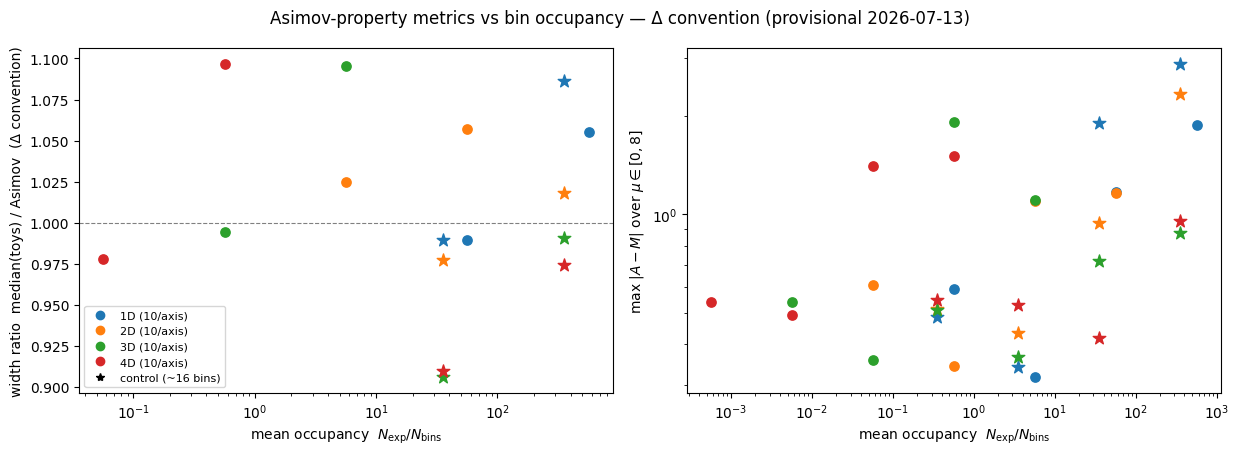

In [10]:
fig, (axr, axd) = plt.subplots(1, 2, figsize=(12.5, 4.6))
colors = {1: 'C0', 2: 'C1', 3: 'C2', 4: 'C3'}
for (cname, L), t in TAB.items():
    d = int(cname[-2]); ctl = cname.startswith('ctl')
    m = '*' if ctl else 'o'
    if np.isfinite(t['ratio']):
        axr.scatter(t['occ'], t['ratio'], color=colors[d], marker=m, s=90 if ctl else 45, zorder=3)
    axd.scatter(t['occ'], t['maxdiff'], color=colors[d], marker=m, s=90 if ctl else 45, zorder=3)
for ax, ylab in ((axr, 'width ratio  median(toys) / Asimov  (Δ convention)'), (axd, r'max $|A-M|$ over $\mu\in[0,8]$')):
    ax.set_xscale('log'); ax.set_xlabel(r'mean occupancy  $N_{\rm exp}/N_{\rm bins}$'); ax.set_ylabel(ylab)
axr.axhline(1, color='grey', lw=0.8, ls='--'); axd.set_yscale('log')
handles = [plt.Line2D([], [], color=colors[d], marker='o', ls='', label=f'{d}D (10/axis)') for d in colors]
handles += [plt.Line2D([], [], color='k', marker='*', ls='', label='control (~16 bins)')]
axr.legend(handles=handles, fontsize=8)
fig.suptitle('Asimov-property metrics vs bin occupancy — Δ convention (provisional 2026-07-13)'); fig.tight_layout(); plt.show()

## 9. Save scan tensors

In [11]:
OUT = os.path.join(ROOT, 'output', 'dim')
for (cname, L), r in RES.items():
    dd = os.path.join(OUT, f'{cname}_lumi_{int(L)}'); os.makedirs(dd, exist_ok=True)
    torch.save(MU_SCAN, os.path.join(dd, 'poi_scan.pt'))
    torch.save(r['nll_asimov'], os.path.join(dd, 'nll_scan_asimov.pt'))
    torch.save(r['nll_toys'], os.path.join(dd, 'nll_scan_toys.pt'))
print('saved under', OUT)

saved under /project/atlas/Users/mfernand/SBI_shortcomings/output/dim


## 10. MC-statistical relevance per configuration (Phase-3 plan item 8 — prong-2 gate)

The proposed fix #3 adds MC-statistical uncertainties (Barlow–Beeston-type). Gate question: are they
even relevant here? Per bin, the effective MC sample size is $n_{\rm eff,b}=(\sum w)^2/\sum w^2$ and
the fractional MC error on $\nu_b$ is $1/\sqrt{n_{\rm eff,b}}$ — independent of luminosity (the same
300k events serve all L).

In [12]:
w_np = np.asarray(w_sm)
NEFF = {}
print(f"{'config':>8} {'bins':>6} {'occupied':>9} {'median MC err':>14} {'worst-decile err':>17} {'frac nu in bins>10% err':>24}")
for cname,(names,axes) in CONFIGS.items():
    hw  = hist.Hist(*axes); hw.fill(*[OBS[nm] for nm in names], weight=w_np)
    hw2 = hist.Hist(*axes); hw2.fill(*[OBS[nm] for nm in names], weight=w_np**2)
    sw, sw2 = hw.values().flatten(), hw2.values().flatten()
    occm = sw > 0
    neff = np.where(occm, sw**2/np.maximum(sw2,1e-300), 0.0)
    NEFF[cname] = neff                                          # kept for the BB-lite overlay (§11)
    np.save(os.path.join(OUT, f'{cname}_neff.npy'), neff)
    if cname.startswith('ctl'): continue
    relerr = np.where(occm, 1/np.sqrt(np.maximum(neff,1e-300)), 0.0)
    frac_bad = sw[relerr>0.10].sum()/sw.sum()
    print(f"{cname:>8} {len(sw):>6} {occm.sum():>9} {np.median(relerr[occm]):>13.1%} "
          f"{np.percentile(relerr[occm],90):>16.1%} {frac_bad:>23.1%}")

  config   bins  occupied  median MC err  worst-decile err  frac nu in bins>10% err
  occ_1d     10        10          1.2%             4.7%                    0.0%
  occ_2d    100       100          6.4%            28.4%                    0.7%
  occ_3d   1000       912         22.4%            73.3%                    5.5%
  occ_4d  10000      4953         51.0%           100.0%                   19.8%


## 11. BB-lite overlay — MC-stat uncertainties in every scenario (Phase-3 items 8a–8b)

**Decision (Marta, 2026-07-13): MC-stat uncertainties are included in every scenario**, overriding
the document-and-skip recommendation of §10. Implementation: **Barlow–Beeston-lite** — one
multiplicative nuisance $\gamma_b$ per bin, constrained by an auxiliary Poisson measurement of the
effective MC count $\tau_b = n_{\rm eff,b} = (\sum w)^2/\sum w^2$. The per-bin profile is
closed-form, $\hat\gamma_b = (n_b + \tau_b)/(\nu_b(\mu) + \tau_b)$, so the scan stays fully
vectorised (`stats/binned.py`, new `*_bblite` functions; constraint written relative to
$\gamma=1$ for float32 stability).

Two exactness checks run first (both must hold to machine precision): $n_{\rm eff}\to\infty$
reproduces the plain scan, and the Asimov $\hat\mu$ stays exactly 1 (at $\mu=1$, $n=\nu$ forces
$\hat\gamma\equiv 1$). The table then repeats the §6 metrics with BB-lite profiling on the same
toys (paired comparison). Expected: 1D–2D essentially unchanged (percent-level MC errors);
3D–4D Asimov intervals widen (profiling flattens the scan where MC errors are large).

In [13]:
from stats.binned import poisson_log_likelihood_scan_bblite, poisson_log_likelihood_scan_toys_bblite

def nll_toys_chunked_bb(n_obs, nu_exp, neff):
    out = []
    for t0 in range(0, n_obs.shape[1], TOY_CHUNK):
        out.append(-2 * poisson_log_likelihood_scan_toys_bblite(n_obs[:, t0:t0+TOY_CHUNK], nu_exp, neff))
    return torch.cat(out, dim=1)

# --- exactness checks (occ_1d @ 1000 fb^-1) --------------------------------------
nu_a = torch.tensor(UNIT['occ_1d'][0] * 1000.); nu_e = torch.tensor(UNIT['occ_1d'][1] * 1000.)
neff1 = torch.tensor(NEFF['occ_1d'], dtype=torch.float32)
plain = -2 * poisson_log_likelihood_scan(nu_a, nu_e)
limit = -2 * poisson_log_likelihood_scan_bblite(nu_a, nu_e, torch.full_like(neff1, 1e12))
assert float(((plain - plain.min()) - (limit - limit.min())).abs().max()) < 1e-3, 'inf-n_eff limit failed'
bb_a1 = -2 * poisson_log_likelihood_scan_bblite(nu_a, nu_e, neff1)
assert abs(interval(bb_a1)[0] - 1.0) < 1e-9, 'Asimov muhat moved under BB-lite'
print('checks passed: n_eff -> inf reproduces the plain scan; Asimov muhat stays exactly 1\n')

# --- 32-point overlay: plain vs BB-lite, Δ-convention metrics --------------------
BBTAB = {}
print(f"{'config':>8} {'lumi':>6} {'w_A':>7} {'w_A_bb':>7} {'ratio_D':>8} {'ratio_D_bb':>10} {'mu_A_bb':>8}")
for (cname, L), r in RES.items():
    neff_t = torch.tensor(NEFF[cname], dtype=torch.float32)
    nu_a = torch.tensor(UNIT[cname][0] * L); nu_e = torch.tensor(UNIT[cname][1] * L)
    nll_a_bb = -2 * poisson_log_likelihood_scan_bblite(nu_a, nu_e, neff_t)
    nll_t_bb = nll_toys_chunked_bb(r['n_obs'], nu_e, neff_t)
    finite = torch.isfinite(nll_t_bb).all(dim=0)
    med_d_bb, _ = med_curves(nll_t_bb[:, finite])
    ha_b, la_b, ua_b = interval(nll_a_bb); hm_b, lm_b, um_b = interval(med_d_bb)
    wab, wmb = ua_b - la_b, um_b - lm_b
    t = TAB[(cname, L)]
    BBTAB[(cname, L)] = dict(wa_bb=wab, ratio_bb=wmb/wab, mu_a_bb=ha_b)
    print(f"{cname:>8} {L:>6.0f} {t['wa']:>7.3f} {wab:>7.3f} {float(t['ratio']):>8.3f} {wmb/wab:>10.3f} {ha_b:>8.2f}")
    dd = os.path.join(OUT, f'{cname}_lumi_{int(L)}')
    torch.save(nll_a_bb, os.path.join(dd, 'nll_scan_asimov_bblite.pt'))
    torch.save(nll_t_bb, os.path.join(dd, 'nll_scan_toys_bblite.pt'))
print('\nBB-lite tensors saved under', OUT)

checks passed: n_eff -> inf reproduces the plain scan; Asimov muhat stays exactly 1

  config   lumi     w_A  w_A_bb  ratio_D ratio_D_bb  mu_A_bb


  occ_1d      1     nan     nan      nan        nan     1.00
  occ_2d      1     nan     nan      nan        nan     1.00


  occ_3d      1     nan     nan      nan        nan     1.00


  occ_4d      1     nan     nan      nan        nan     1.00
  ctl_1d      1     nan     nan      nan        nan     1.00
  ctl_2d      1     nan     nan      nan        nan     1.00
  ctl_3d      1     nan     nan      nan        nan     1.00
  ctl_4d      1     nan     nan      nan        nan     1.00
  occ_1d     10     nan     nan      nan        nan     1.00
  occ_2d     10     nan     nan      nan        nan     1.00


  occ_3d     10     nan     nan      nan        nan     1.00


  occ_4d     10     nan     nan      nan        nan     1.00
  ctl_1d     10     nan     nan      nan        nan     1.00
  ctl_2d     10     nan     nan      nan        nan     1.00
  ctl_3d     10     nan     nan      nan        nan     1.00
  ctl_4d     10     nan     nan      nan        nan     1.00
  occ_1d    100   1.798   1.799    0.990      0.989     1.00
  occ_2d    100   1.799   1.800    1.025      1.026     1.00


  occ_3d    100   1.787   1.788    0.994      0.994     1.00


  occ_4d    100   1.765   1.766    0.978      0.978     1.00
  ctl_1d    100   1.793   1.794    0.989      0.990     1.00
  ctl_2d    100   1.848   1.849    0.977      0.977     1.00
  ctl_3d    100   1.919   1.921    0.906      0.906     1.00
  ctl_4d    100   1.923   1.925    0.910      0.910     1.00
  occ_1d   1000   0.803   0.822    1.055      1.045     1.00
  occ_2d   1000   0.799   0.817    1.057      1.043     1.00


  occ_3d   1000   0.775   0.790    1.096      1.083     1.00


  occ_4d   1000   0.723   0.736    1.097      1.106     1.00
  ctl_1d   1000   0.795   0.811    1.086      1.077     1.00
  ctl_2d   1000   0.902   0.922    1.018      1.010     1.00
  ctl_3d   1000   1.050   1.062    0.990      0.989     1.00
  ctl_4d   1000   1.053   1.066    0.974      0.972     1.00

BB-lite tensors saved under /project/atlas/Users/mfernand/SBI_shortcomings/output/dim


## What this shows (rewritten 2026-07-13 — Δ-primary convention, BB-lite included)

**Convention (adopted 2026-07-13, ⚠ provisional — not yet discussed with team/Tei; ratification
via the plan item-7 message):** primary comparator = np.median of per-toy min-subtracted (Δ)
curves — the convention matching the scalar-statistic theorem (foundations §8); np.median of raw
curves is the secondary, estimator-variance observation; torch.median retired (lower-middle
element at even toy counts).

1. **Under the Δ convention there is no dimensionality effect in the width ratio.** At
1000 fb$^{-1}$ ratio_D moves only from 1.06 (1D) to 1.10 (4D); at 100 fb$^{-1}$ it is 0.98–1.03;
the ~16-bin controls sit in the same band. The historical headline ("1.08 → 0.44 at 4D/1000")
was the raw-curve convention compounded by the torch.median even-n quirk — decomposition on
identical tensors: 0.44 (torch-raw) / 0.71 (np-raw) / 1.10 (Δ) (`bartlett_correction.ipynb`).

2. **The raw-median narrowing survives as an estimator-variance observation** (ratio_raw column):
1.08 at 1D/1000 fb$^{-1}$ but 0.58–0.71 at 2D–4D. Raw curves mix per-toy location scatter with
width, and that scatter grows with cell count — a statement about the $\hat\mu$ distribution,
not about interval widths.

3. **The occupancy story lives in coverage, not in the Δ width ratio**: the convention-free
coverage analysis (`bartlett_correction.ipynb`) shows the high-L pathology is the interference
rate fold (under-coverage ≈0.62 at 1000 fb$^{-1}$, occupancy-independent), while low occupancy
shows up as open intervals at 1–10 fb$^{-1}$ and noisy medians — not as a width-ratio trend.

4. **BB-lite (§11; decision 2026-07-13: MC-stat uncertainties in every scenario):** exactness
checks pass ($n_{\rm eff}\to\infty$ limit exact; Asimov $\hat\mu = 1.000$ at all 32 points). The
effect on the metrics is marginal: Asimov 1σ widths grow ≤0.2% at 100 fb$^{-1}$ and 1.8–2.4% at
1000 fb$^{-1}$, and ratio_D moves by ≤0.013 — even at 4D (51% median per-bin MC error) the *data*
statistical error per bin dominates. MC-stat treatment is now included everywhere without
altering any conclusion; §10 stays as the relevance gate for quantitative per-bin yield claims.

5. Asimov $\hat\mu = 1.000$ at every one of the 32 points, plain **and** BB-lite; zero non-finite
toys.

**Follow-ups:** effective-occupancy variable for the collapse plot; NSBI overlay once path A
lands (same panels, Δ convention); convention ratification with team/Tei (plan item 7).